# Visualizing cross-validation behavior: scikit-learn vs Moxie

**Reference example:** `../scikit-learn/examples/model_selection/plot_cv_indices.py` at scikit-learn
`4358542a1bd39af2e7e1cbace8b9fed067473c5b`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/model_selection/plot_cv_indices.html)).

**Scenario:** 100 samples with three imbalanced classes (10/30/60) and ten groups drawn from a Dirichlet prior
(`RandomState(1338)`). The example draws the train/test assignment of every fold of `KFold`,
`StratifiedKFold`, `GroupKFold`, `StratifiedGroupKFold`, `ShuffleSplit`, `GroupShuffleSplit`,
`StratifiedShuffleSplit` and `TimeSeriesSplit` with `n_splits=4`.

**Adaptations:**
- The example's last loop leaves `random_state=None` on the three shuffle splitters, so its figure changes on
  every run. The comparison uses `random_state=0` for `ShuffleSplit`, `GroupShuffleSplit` and
  `StratifiedShuffleSplit` on both sides; the official cells still run unchanged (figures only).
- Beyond the example, the same data drive every other public splitter (`LeaveOneOut`, `LeavePOut`,
  `LeaveOneGroupOut`, `LeavePGroupsOut`, `RepeatedKFold`, `RepeatedStratifiedKFold`, `PredefinedSplit`),
  shuffled `KFold`/`StratifiedKFold`/`GroupKFold`/`StratifiedGroupKFold`, explicit train/test sizes,
  `TimeSeriesSplit(gap, max_train_size, test_size)`, `check_cv(4, y, classifier=True)`, `get_n_splits`
  and stratified `train_test_split`.
- Data are generated in Python and shared; Moxie splitters take the sample count (`split(n_samples, y=..., groups=...)`)
  and Int64 labels/groups, a documented native adaptation.

**Determinism:** with explicit seeds every splitter is deterministic, and Moxie reproduces NumPy's
`RandomState` stream, so fold indices must match **exactly**, including the order of indices inside each fold.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("model_selection/plot_cv_indices")

## 1. scikit-learn (Python reference)

The example code, unchanged except for smaller figures (dpi 60).

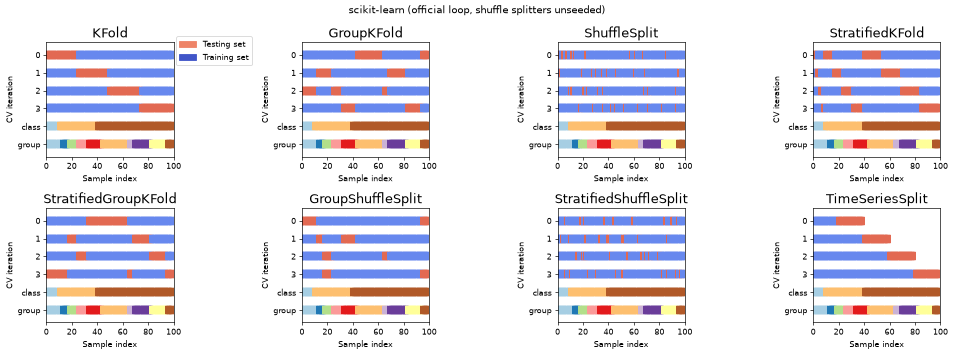

In [2]:
import warnings
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch

from sklearn.model_selection import (
    GroupKFold,
    GroupShuffleSplit,
    KFold,
    ShuffleSplit,
    StratifiedGroupKFold,
    StratifiedKFold,
    StratifiedShuffleSplit,
    TimeSeriesSplit,
)

plt.rcParams["figure.dpi"] = 60
rng = np.random.RandomState(1338)
cmap_data = plt.cm.Paired
cmap_cv = plt.cm.coolwarm
n_splits = 4

# Generate the class/group data
n_points = 100
X = rng.randn(100, 10)

percentiles_classes = [0.1, 0.3, 0.6]
y = np.hstack([[ii] * int(100 * perc) for ii, perc in enumerate(percentiles_classes)])

# Generate uneven groups
group_prior = rng.dirichlet([2] * 10)
groups = np.repeat(np.arange(10), rng.multinomial(100, group_prior))


def plot_cv_indices(cv, X, y, group, ax, n_splits, lw=10):
    """Create a sample plot for indices of a cross-validation object."""
    use_groups = "Group" in type(cv).__name__
    groups = group if use_groups else None
    # Generate the training/testing visualizations for each CV split
    for ii, (tr, tt) in enumerate(cv.split(X=X, y=y, groups=groups)):
        # Fill in indices with the training/test groups
        indices = np.array([np.nan] * len(X))
        indices[tt] = 1
        indices[tr] = 0

        # Visualize the results
        ax.scatter(
            range(len(indices)),
            [ii + 0.5] * len(indices),
            c=indices,
            marker="_",
            lw=lw,
            cmap=cmap_cv,
            vmin=-0.2,
            vmax=1.2,
        )

    # Plot the data classes and groups at the end
    ax.scatter(
        range(len(X)), [ii + 1.5] * len(X), c=y, marker="_", lw=lw, cmap=cmap_data
    )

    ax.scatter(
        range(len(X)), [ii + 2.5] * len(X), c=group, marker="_", lw=lw, cmap=cmap_data
    )

    # Formatting
    yticklabels = list(range(n_splits)) + ["class", "group"]
    ax.set(
        yticks=np.arange(n_splits + 2) + 0.5,
        yticklabels=yticklabels,
        xlabel="Sample index",
        ylabel="CV iteration",
        ylim=[n_splits + 2.2, -0.2],
        xlim=[0, 100],
    )
    ax.set_title("{}".format(type(cv).__name__), fontsize=15)
    return ax


cvs = [
    KFold,
    GroupKFold,
    ShuffleSplit,
    StratifiedKFold,
    StratifiedGroupKFold,
    GroupShuffleSplit,
    StratifiedShuffleSplit,
    TimeSeriesSplit,
]

fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for cv, ax in zip(cvs, axes.ravel()):
    this_cv = cv(n_splits=n_splits)
    plot_cv_indices(this_cv, X, y, groups, ax, n_splits)
axes[0, 0].legend(
    [Patch(color=cmap_cv(0.8)), Patch(color=cmap_cv(0.02))],
    ["Testing set", "Training set"],
    loc=(1.02, 0.8),
)
fig.suptitle("scikit-learn (official loop, shuffle splitters unseeded)")
plt.tight_layout()
plt.show()

In [3]:
# Seeded reference for every comparison below.
from sklearn.model_selection import (LeaveOneGroupOut, LeaveOneOut, LeavePGroupsOut, LeavePOut,
                                     PredefinedSplit, RepeatedKFold, RepeatedStratifiedKFold,
                                     check_cv, train_test_split)

k = n_splits
seeded = {
    "KFold": (KFold(k), 100),
    "StratifiedKFold": (StratifiedKFold(k), 100),
    "GroupKFold": (GroupKFold(k), 100),
    "StratifiedGroupKFold": (StratifiedGroupKFold(k), 100),
    "ShuffleSplit": (ShuffleSplit(k, random_state=0), 100),
    "GroupShuffleSplit": (GroupShuffleSplit(k, random_state=0), 100),
    "StratifiedShuffleSplit": (StratifiedShuffleSplit(k, random_state=0), 100),
    "TimeSeriesSplit": (TimeSeriesSplit(k), 100),
    "KFold_shuffle": (KFold(k, shuffle=True, random_state=0), 100),
    "StratifiedKFold_shuffle": (StratifiedKFold(k, shuffle=True, random_state=0), 100),
    "GroupKFold_shuffle": (GroupKFold(k, shuffle=True, random_state=0), 100),
    "StratifiedGroupKFold_shuffle": (StratifiedGroupKFold(k, shuffle=True, random_state=0), 100),
    "RepeatedKFold": (RepeatedKFold(n_splits=k, n_repeats=2, random_state=0), 100),
    "RepeatedStratifiedKFold": (RepeatedStratifiedKFold(n_splits=k, n_repeats=2, random_state=0), 100),
    "TimeSeriesSplit_gap": (TimeSeriesSplit(k, max_train_size=30, test_size=10, gap=2), 100),
    "LeaveOneGroupOut": (LeaveOneGroupOut(), 100),
    "LeavePGroupsOut": (LeavePGroupsOut(2), 100),
    "LeaveOneOut": (LeaveOneOut(), 100),
    "LeavePOut": (LeavePOut(2), 10),
    "PredefinedSplit": (PredefinedSplit(groups % 3 - 1), 100),
    "ShuffleSplit_sizes": (ShuffleSplit(k, test_size=0.25, train_size=0.5, random_state=0), 100),
    "StratifiedShuffleSplit_count": (StratifiedShuffleSplit(k, test_size=12, random_state=0), 100),
    "check_cv": (check_cv(k, y, classifier=True), 100),
}


def folds(cv, n):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")  # "groups parameter is ignored" warnings
        pairs = list(cv.split(X[:n], y[:n], groups[:n]))
    member = np.full((len(pairs), n), -1)
    for f, (tr, tt) in enumerate(pairs):
        member[f, tr] = 0
        member[f, tt] = 1
    return member, np.concatenate([tr for tr, _ in pairs]), np.concatenate([tt for _, tt in pairs])


sk = {name: folds(cv, n) for name, (cv, n) in seeded.items()}
sk_n_splits = [KFold(k).get_n_splits(), GroupKFold(k).get_n_splits(),
               LeaveOneGroupOut().get_n_splits(groups=groups), LeavePGroupsOut(2).get_n_splits(groups=groups),
               LeaveOneOut().get_n_splits(X), LeavePOut(2).get_n_splits(X[:10]),
               RepeatedKFold(n_splits=k, n_repeats=2).get_n_splits(),
               PredefinedSplit(groups % 3 - 1).get_n_splits(), GroupShuffleSplit().get_n_splits()]
sk_tts = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
print({name: v[0].shape for name, v in sk.items()})
nb.share(X=X, y=y.astype(np.int64), groups=groups.astype(np.int64))

{'KFold': (4, 100), 'StratifiedKFold': (4, 100), 'GroupKFold': (4, 100), 'StratifiedGroupKFold': (4, 100), 'ShuffleSplit': (4, 100), 'GroupShuffleSplit': (4, 100), 'StratifiedShuffleSplit': (4, 100), 'TimeSeriesSplit': (4, 100), 'KFold_shuffle': (4, 100), 'StratifiedKFold_shuffle': (4, 100), 'GroupKFold_shuffle': (4, 100), 'StratifiedGroupKFold_shuffle': (4, 100), 'RepeatedKFold': (8, 100), 'RepeatedStratifiedKFold': (8, 100), 'TimeSeriesSplit_gap': (4, 100), 'LeaveOneGroupOut': (10, 100), 'LeavePGroupsOut': (45, 100), 'LeaveOneOut': (100, 100), 'LeavePOut': (45, 10), 'PredefinedSplit': (2, 100), 'ShuffleSplit_sizes': (4, 100), 'StratifiedShuffleSplit_count': (4, 100), 'check_cv': (4, 100)}


## 2. Moxie (native Mojo)

The same splitters through `moxie.model_selection`. Each cursor's `next()` yields an owned `IndexSplit`;
the program records fold membership and the raw train/test index order.

In [4]:
%%mojo cv_indices
from moxie.model_selection import (
    GroupKFold, GroupShuffleSplit, KFold, ShuffleSplit, StratifiedGroupKFold,
    StratifiedKFold, StratifiedShuffleSplit, TimeSeriesSplit, LeaveOneOut,
    LeavePOut, LeaveOneGroupOut, LeavePGroupsOut, RepeatedKFold,
    RepeatedStratifiedKFold, PredefinedSplit, IndexArray, IndexSplit,
    SplitCursor, SplitSize, train_test_split, check_cv,
)
from moxie_nb_io import load, save, save_ints
from numojo import NDArray, Shape, Item


def emit[C: SplitCursor & Deinitable](name: String, var cursor: C, n: Int) raises:
    """Save fold membership (1 = test, 0 = train, -1 = unused, as in the example's
    plot) plus every fold's train and test indices concatenated in emitted order."""
    var folds = List[IndexSplit]()
    while True:
        var pair = cursor.next()
        if not pair:
            break
        folds.append(pair.value().copy())
    var out = NDArray[DType.int64](Shape(len(folds), n))
    var train = List[Int]()
    var test = List[Int]()
    for f in range(len(folds)):
        for i in range(n):
            out[Item(f, i)] = -1
        for i in range(folds[f].train.size):
            out[Item(f, Int(folds[f].train[Item(i)]))] = 0
            train.append(Int(folds[f].train[Item(i)]))
        for i in range(folds[f].test.size):
            out[Item(f, Int(folds[f].test[Item(i)]))] = 1
            test.append(Int(folds[f].test[Item(i)]))
    save(name, out)
    save_ints(name + "_train", train)
    save_ints(name + "_test", test)


def main() raises:
    var X = load("X")
    var y = load[DType.int64]("y")
    var groups = load[DType.int64]("groups")
    var n = X.shape[0]
    var k = 4
    emit("KFold", KFold(k).split(n), n)
    emit("StratifiedKFold", StratifiedKFold(k).split(n, y=y.copy()), n)
    emit("GroupKFold", GroupKFold(k).split(n, groups=groups.copy()), n)
    emit("StratifiedGroupKFold", StratifiedGroupKFold(k).split(n, y=y.copy(), groups=groups.copy()), n)
    emit("ShuffleSplit", ShuffleSplit(k, random_state=0).split(n), n)
    emit("GroupShuffleSplit", GroupShuffleSplit(k, random_state=0).split(n, groups=groups.copy()), n)
    emit("StratifiedShuffleSplit", StratifiedShuffleSplit(k, random_state=0).split(n, y=y.copy()), n)
    emit("TimeSeriesSplit", TimeSeriesSplit(k).split(n), n)

    # Beyond the example: the remaining splitters, shuffled variants and helpers.
    emit("KFold_shuffle", KFold(k, shuffle=True, random_state=0).split(n), n)
    emit("StratifiedKFold_shuffle", StratifiedKFold(k, shuffle=True, random_state=0).split(n, y=y.copy()), n)
    emit("GroupKFold_shuffle", GroupKFold(k, shuffle=True, random_state=0).split(n, groups=groups.copy()), n)
    emit("StratifiedGroupKFold_shuffle", StratifiedGroupKFold(k, shuffle=True, random_state=0).split(n, y=y.copy(), groups=groups.copy()), n)
    emit("RepeatedKFold", RepeatedKFold(n_splits=k, n_repeats=2, random_state=0).split(n), n)
    emit("RepeatedStratifiedKFold", RepeatedStratifiedKFold(n_splits=k, n_repeats=2, random_state=0).split(n, y=y.copy()), n)
    emit("TimeSeriesSplit_gap", TimeSeriesSplit(k, max_train_size=30, test_size=10, gap=2).split(n), n)
    emit("LeaveOneGroupOut", LeaveOneGroupOut().split(n, groups=groups.copy()), n)
    emit("LeavePGroupsOut", LeavePGroupsOut(2).split(n, groups=groups.copy()), n)
    emit("LeaveOneOut", LeaveOneOut().split(n), n)
    emit("LeavePOut", LeavePOut(2).split(10), 10)
    var test_fold = IndexArray(Shape(n))
    for i in range(n):
        test_fold[Item(i)] = groups[Item(i)] % 3 - 1
    emit("PredefinedSplit", PredefinedSplit(test_fold).split(), n)
    emit("ShuffleSplit_sizes", ShuffleSplit(k, test_size=SplitSize(0.25), train_size=SplitSize(0.5), random_state=0).split(n), n)
    emit("StratifiedShuffleSplit_count", StratifiedShuffleSplit(k, test_size=SplitSize(12), random_state=0).split(n, y=y.copy()), n)
    emit("check_cv", check_cv(k, y.copy(), classifier=True).split(n, y=y.copy()), n)
    var counts = List[Int]()
    counts.append(KFold(k).get_n_splits())
    counts.append(GroupKFold(k).get_n_splits())
    counts.append(LeaveOneGroupOut().get_n_splits(groups=groups.copy()))
    counts.append(LeavePGroupsOut(2).get_n_splits(groups=groups.copy()))
    counts.append(LeaveOneOut().get_n_splits(n))
    counts.append(LeavePOut(2).get_n_splits(10))
    counts.append(RepeatedKFold(n_splits=k, n_repeats=2).get_n_splits())
    counts.append(PredefinedSplit(test_fold).get_n_splits())
    counts.append(GroupShuffleSplit().get_n_splits())
    save_ints("n_splits", counts)
    var parts = train_test_split(X, y, test_size=SplitSize(0.25), random_state=42, stratify=y.copy())
    save("tts_X_train", parts[0])
    save("tts_X_test", parts[1])
    save("tts_y_train", parts[2])
    save("tts_y_test", parts[3])


## 3. Side by side and parity

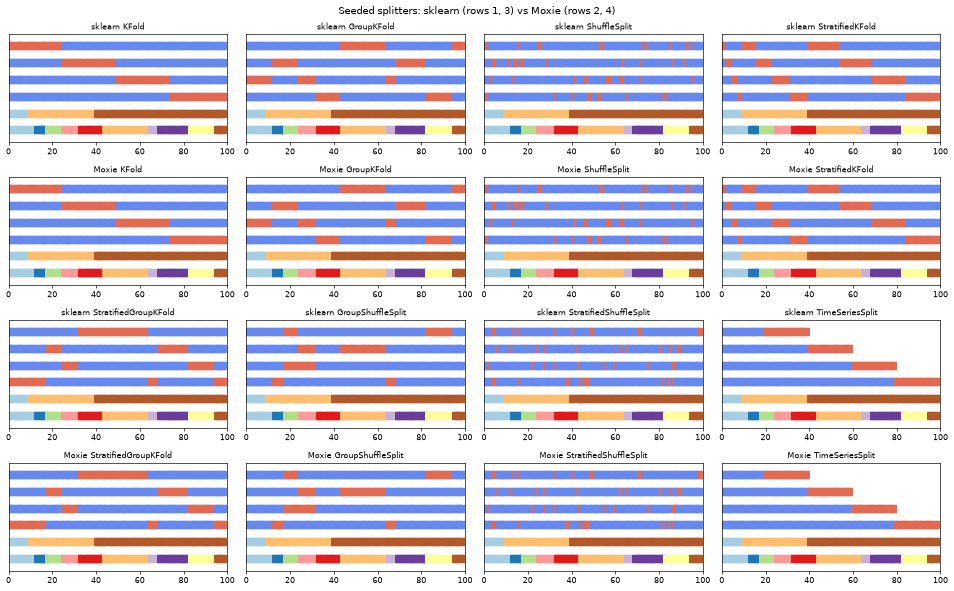

In [5]:
mx = nb.results["cv_indices"]


def draw(ax, member, title):
    for ii, row in enumerate(member):
        ind = np.where(row < 0, np.nan, row.astype(float))
        ax.scatter(range(member.shape[1]), [ii + 0.5] * member.shape[1], c=ind, marker="_",
                   lw=10, cmap=cmap_cv, vmin=-0.2, vmax=1.2)
    ax.scatter(range(100), [ii + 1.5] * 100, c=y, marker="_", lw=10, cmap=cmap_data)
    ax.scatter(range(100), [ii + 2.5] * 100, c=groups, marker="_", lw=10, cmap=cmap_data)
    ax.set(ylim=[member.shape[0] + 2.2, -0.2], xlim=[0, 100], yticks=[])
    ax.set_title(title, fontsize=10)


names = ["KFold", "GroupKFold", "ShuffleSplit", "StratifiedKFold",
         "StratifiedGroupKFold", "GroupShuffleSplit", "StratifiedShuffleSplit", "TimeSeriesSplit"]
fig, axes = plt.subplots(4, 4, figsize=(16, 10))
for i, name in enumerate(names):
    r, c = divmod(i, 4)
    draw(axes[2 * (r), c], sk[name][0], "sklearn " + name)
    draw(axes[2 * r + 1, c], mx[name], "Moxie " + name)
fig.suptitle("Seeded splitters: sklearn (rows 1, 3) vs Moxie (rows 2, 4)")
plt.tight_layout()
plt.show()

moxie_nb.side_by_side(sklearn=sk["StratifiedGroupKFold"][0][:, :30], moxie=mx["StratifiedGroupKFold"][:, :30])

In [6]:
for name, (member, train, test) in sk.items():
    nb.compare(name + " membership", member, mx[name], exact=True)
    nb.compare(name + " train order", train, mx[name + "_train"], exact=True)
    nb.compare(name + " test order", test, mx[name + "_test"], exact=True)
nb.compare("get_n_splits", sk_n_splits, mx["n_splits"], exact=True)
for label, ref, got in zip(["X_train", "X_test", "y_train", "y_test"], sk_tts,
                           [mx["tts_X_train"], mx["tts_X_test"], mx["tts_y_train"], mx["tts_y_test"]]):
    nb.compare("train_test_split " + label, ref, got, exact=True)
    assert ref.dtype == got.dtype, (label, ref.dtype, got.dtype)
nb.note("groups warnings", "ADAPTED",
        "sklearn warns when groups are passed to non-group splitters; Moxie has no warning channel "
        "and non-group splitters simply take no groups argument")
nb.note("random_state=None", "ADAPTED",
        "Moxie has no hidden global RNG: unseeded shuffles need an explicit mutable RandomState "
        "(split(n, rng)); the comparison seeds both sides")
nb.report()
nb.assert_parity()

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
KFold membership,PASS,"(4, 100)","(4, 100)",,,exact,0 mismatches,
KFold train order,PASS,"(300,)","(300,)",,,exact,0 mismatches,
KFold test order,PASS,"(100,)","(100,)",,,exact,0 mismatches,
StratifiedKFold membership,PASS,"(4, 100)","(4, 100)",,,exact,0 mismatches,
StratifiedKFold train order,PASS,"(300,)","(300,)",,,exact,0 mismatches,
StratifiedKFold test order,PASS,"(100,)","(100,)",,,exact,0 mismatches,
GroupKFold membership,PASS,"(4, 100)","(4, 100)",,,exact,0 mismatches,
GroupKFold train order,PASS,"(300,)","(300,)",,,exact,0 mismatches,
GroupKFold test order,PASS,"(100,)","(100,)",,,exact,0 mismatches,
StratifiedGroupKFold membership,PASS,"(4, 100)","(4, 100)",,,exact,0 mismatches,
